# Mind & Mortality: Forecasting Suicide Rates in Mexico Using Decision Trees and Panel Data

# By: Jorge Antonio Toscano Lara

# 1. Theoretical Foundations
Decision Tree Regressors in Time Series
Decision Trees (DT) are non-parametric supervised learning algorithms. Unlike ARIMA models that rely on autocorrelation, a DT predicts the target variable by learning simple decision rules inferred from the data features.

Mathematical Foundation: Variance Reduction
For regression tasks, the DT partitions the data space into regions by selecting splits that minimize the Mean Squared Error (MSE) at each node. If a node $m$ represents a region $R_m$ with $N_m$ observations, the predicted value $\hat{y}_m$ is the mean of the target values in that region:


$$\hat{y}_m = \frac{1}{N_m} \sum_{i \in R_m} y_i$$

The algorithm chooses a feature $j$ and a threshold $s$ to split the node into two child nodes ($R_1, R_2$) by minimizing the cost function:

$$J(j, s) = \sum_{i \in R_1(j, s)} (y_i - \hat{y}_1)^2 + \sum_{i \in R_2(j, s)} (y_i - \hat{y}_2)^2$$

Limitations in Time Series: Extrapolation
Because the prediction $\hat{y}_m$ is strictly an average of historical observations falling into a specific leaf node, Decision Trees cannot extrapolate. They are incapable of predicting values higher or lower than the maximum or minimum values seen during training.

# 2. Exploratory Data Analysis


In [1]:
# 2. ADVANCED EXPLORATORY DATA ANALYSIS (EDA)
# ---------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# --- 2.1 DATA PREPARATION FOR EDA ---
# (We load and merge the data to analyze relationships in the same year)

# Load Suicides
df_suicides = pd.read_excel("Defunciones registradas por suicidio por entidad federativa y causa según sexo.xlsx", header=6)
indices_to_keep = [0]
for i in range(2, len(df_suicides.columns)):
    col_year = str(df_suicides.columns[i]).split('.')[0]
    sub_col = str(df_suicides.iloc[0, i])
    if col_year.isdigit() and 2014 <= int(col_year) <= 2024 and sub_col == 'Total':
        indices_to_keep.append(i)

df_s_filtered = df_suicides[(df_suicides['Causa'] == 'Total') & (df_suicides['Entidad federativa'] != 'Total')]
df_s_clean = df_s_filtered.iloc[:, indices_to_keep].copy()
df_s_clean.columns = ['State'] + [str(year) for year in range(2014, 2025)]
df_target = df_s_clean.melt(id_vars=['State'], var_name='Year', value_name='Total_Suicides')
df_target['Year'] = df_target['Year'].astype(int)
df_target['Total_Suicides'] = pd.to_numeric(df_target['Total_Suicides'])

In [3]:
# Load Mental Health
df_health = pd.read_excel("TASADE~1.XLS", header=6)
total_indices = [i for i, col in enumerate(df_health.iloc[0]) if str(col) == 'Total']
df_health = df_health[df_health['Entidad federativa'] != 'Estados Unidos Mexicanos']

df_dep = df_health[df_health['Casos seleccionados'] == 'Depresión'].iloc[:, [0] + total_indices].copy()
df_ano = df_health[df_health['Casos seleccionados'] == 'Anorexia y bulimia'].iloc[:, [0] + total_indices].copy()

health_cols = ['State'] + [str(year) for year in range(2014, 2025)]
df_dep.columns = health_cols
df_ano.columns = health_cols

df_dep_long = df_dep.melt(id_vars=['State'], var_name='Year', value_name='Depression_Rate')
df_ano_long = df_ano.melt(id_vars=['State'], var_name='Year', value_name='Anorexia_Rate')
df_dep_long['Year'] = df_dep_long['Year'].astype(int)
df_ano_long['Year'] = df_ano_long['Year'].astype(int)

In [4]:
# Merge into a single EDA DataFrame
df_eda = pd.merge(df_target, df_dep_long, on=['State', 'Year'])
df_eda = pd.merge(df_eda, df_ano_long, on=['State', 'Year'])

In [5]:
# Convert rates to numeric
df_eda['Depression_Rate'] = pd.to_numeric(df_eda['Depression_Rate'])
df_eda['Anorexia_Rate'] = pd.to_numeric(df_eda['Anorexia_Rate'])

In [6]:
# --- 2.2 VISUALIZATIONS ---
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(18, 12))

<Figure size 1800x1200 with 0 Axes>

# Plot 1: Correlation Matrix (Mental Health vs. Suicides)

Text(0.5, 1.0, 'Correlation Matrix: Mental Health vs Suicides')

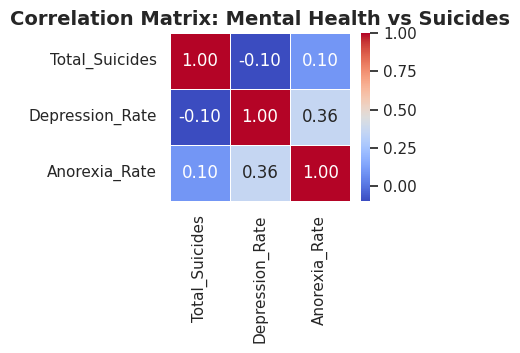

In [7]:
# Plot 1: Correlation Heatmap
ax1 = plt.subplot(2, 2, 1)
corr_matrix = df_eda[['Total_Suicides', 'Depression_Rate', 'Anorexia_Rate']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, ax=ax1)
ax1.set_title('Correlation Matrix: Mental Health vs Suicides', fontsize=14, weight='bold')

The correlation matrix reveals a weak negative correlation (-0.10) between reported Depression Rates and Total Suicides. This unexpected finding suggests that at a state level, absolute suicide volumes do not perfectly align with clinically diagnosed depression rates. This highlights a critical insight: highly populated states may have high suicide totals but lower reported depression rates, possibly due to underdiagnosis or disparities in mental health infrastructure.

# Plot 2: Impact of Depression Rate on Total Suicides (Scatter Plot)

Text(0, 0.5, 'Total Suicides')

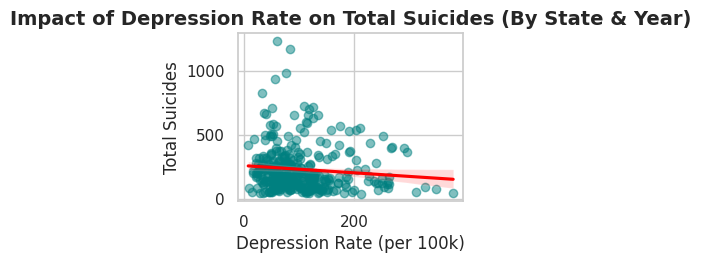

In [8]:
# Plot 2: Scatter Plot with Regression Line (Depression vs Suicides)
ax2 = plt.subplot(2, 2, 2)
sns.regplot(data=df_eda, x='Depression_Rate', y='Total_Suicides', scatter_kws={'alpha':0.5, 'color':'teal'}, line_kws={'color':'red'}, ax=ax2)
ax2.set_title('Impact of Depression Rate on Total Suicides (By State & Year)', fontsize=14, weight='bold')
ax2.set_xlabel('Depression Rate (per 100k)')
ax2.set_ylabel('Total Suicides')

The scatter plot, featuring a slightly negative regression line, visually confirms an inverse trend in the raw data. It demonstrates that geographic regions with the highest absolute number of suicides do not necessarily report the highest density of clinical depression. This paradox emphasizes the need to transition from absolute volumes to standardized mortality rates for a more accurate epidemiological forecasting model.

# Plot 3: Temporal Evolution: Suicides vs. Depression 2014-2024 (Dual-Axis Time Series)

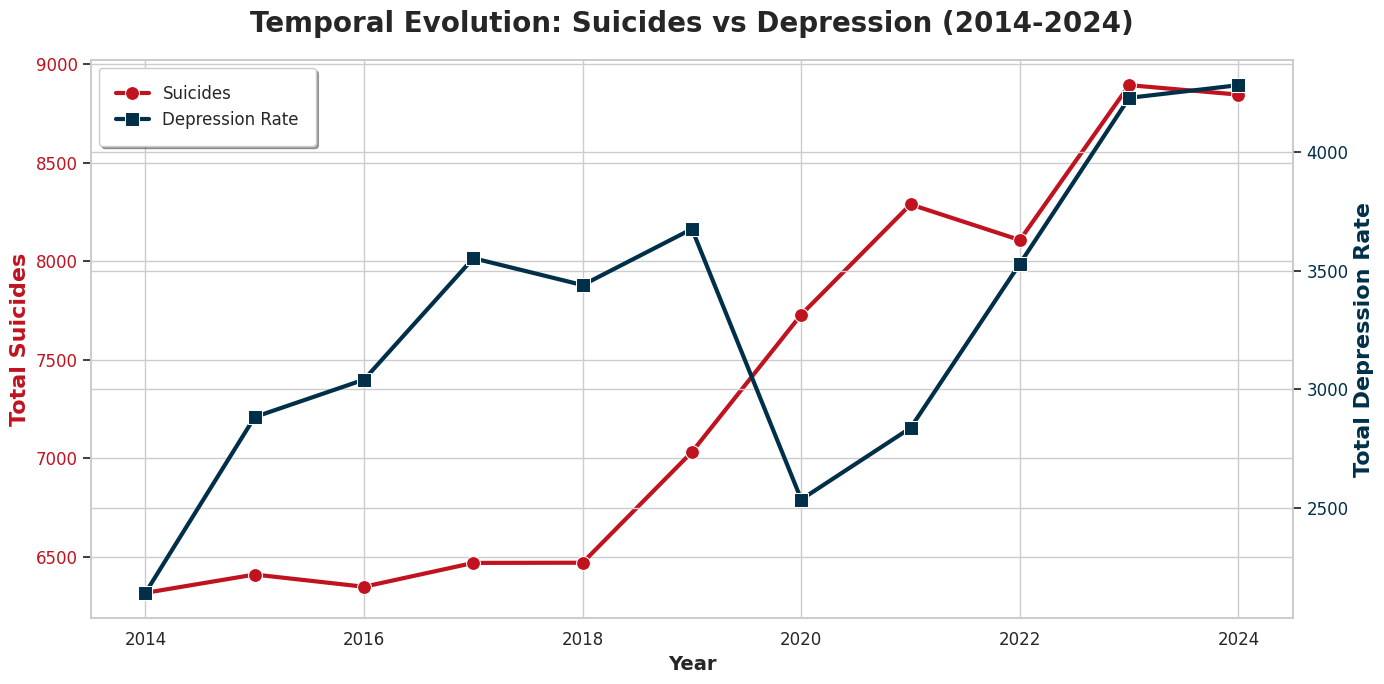

In [9]:
# Plot 3: Dual-Axis Time Series (National Aggregation) - PRESENTATION VERSION
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo visual base
sns.set_theme(style="whitegrid")

# Crear una figura independiente mucho más grande (14x7 pulgadas)
fig, ax3 = plt.subplots(figsize=(14, 7))

# Preparar los datos
national_trend = df_eda.groupby('Year').sum(numeric_only=True).reset_index()

# Configurar Eje Y principal (Izquierdo) - Suicidios
color1 = '#c1121f' # Rojo más oscuro y profesional
ax3.set_xlabel('Year', weight='bold', fontsize=14)
ax3.set_ylabel('Total Suicides', color=color1, weight='bold', fontsize=16)

# Trazar línea de suicidios más gruesa y con marcadores más grandes
sns.lineplot(data=national_trend, x='Year', y='Total_Suicides', marker='o',
             color=color1, ax=ax3, label='Suicides', linewidth=3, markersize=10)

ax3.tick_params(axis='y', labelcolor=color1, labelsize=12)
ax3.tick_params(axis='x', labelsize=12)

# Configurar Eje Y secundario (Derecho) - Depresión
ax3_twin = ax3.twinx()
color2 = '#003049' # Azul marino profundo
ax3_twin.set_ylabel('Total Depression Rate', color=color2, weight='bold', fontsize=16)

# Trazar línea de depresión
sns.lineplot(data=national_trend, x='Year', y='Depression_Rate', marker='s',
             color=color2, ax=ax3_twin, label='Depression Rate', linewidth=3, markersize=10)

ax3_twin.tick_params(axis='y', labelcolor=color2, labelsize=12)

# Título más llamativo y con separación
ax3.set_title('Temporal Evolution: Suicides vs Depression (2014-2024)',
              fontsize=20, weight='bold', pad=20)

# Unificar las leyendas de ambos ejes en un solo cuadro
lines_1, labels_1 = ax3.get_legend_handles_labels()
lines_2, labels_2 = ax3_twin.get_legend_handles_labels()
ax3_twin.get_legend().remove() # Evitar doble leyenda
ax3.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left',
           fontsize=12, frameon=True, shadow=True, borderpad=1)

# Ajuste perfecto de los márgenes para que nada se corte
fig.tight_layout()

# Renderizar
plt.show()

The dual-axis time series reveals a significant decoupling of the two variables during the 2020 pandemic anomaly. While official clinical depression diagnoses dropped sharply in 2020 (likely due to lockdowns and reduced medical consultations), suicide totals began a steep upward trend. This temporal behavior validates that actual mental health crises escalated rapidly, even when official diagnosis rates temporarily plummeted.

# Plot 4: Top 5 States with Highest Suicides (Cross-sectional insight for 2024)

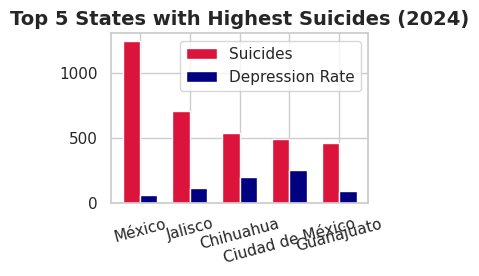

In [10]:
# Plot 4: Top 5 States Comparison (Cross-sectional insight for 2024)
ax4 = plt.subplot(2, 2, 4)
df_2024 = df_eda[df_eda['Year'] == 2024].sort_values(by='Total_Suicides', ascending=False).head(5)
x = np.arange(len(df_2024['State']))
width = 0.35

ax4.bar(x - width/2, df_2024['Total_Suicides'], width, label='Suicides', color='crimson')
ax4.bar(x + width/2, df_2024['Depression_Rate'], width, label='Depression Rate', color='navy')
ax4.set_xticks(x)
ax4.set_xticklabels(df_2024['State'], rotation=15)
ax4.set_title('Top 5 States with Highest Suicides (2024)', fontsize=14, weight='bold')
ax4.legend()

plt.tight_layout()
plt.show()

The comparative bar chart illustrates that the absolute volume of this public health crisis is highly concentrated. By isolating the data for 2024, the chart identifies the State of Mexico, Jalisco, Chihuahua, Mexico City, and Guanajuato as the most critical regions in terms of total incidents. This cross-sectional analysis reveals that highly populated states face the heaviest absolute burden, requiring significant and localized psychological support resources.

# 3. Data Engineering & Sliding Window

In [11]:
# 3. DATA ENGINEERING & SLIDING WINDOW (INTERACTIVE VISUALIZATION)
# ---------------------------------------------------------
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 3.1 LOAD AND MERGE DATA (Creating df_final)
# Load Suicides
df_suicides = pd.read_excel("Defunciones registradas por suicidio por entidad federativa y causa según sexo.xlsx", header=6)
indices_to_keep = [0]
for i in range(2, len(df_suicides.columns)):
    col_year_str = str(df_suicides.columns[i]).split('.')[0]
    sub_col = str(df_suicides.iloc[0, i])
    if col_year_str.isdigit() and 2014 <= int(col_year_str) <= 2024 and sub_col == 'Total':
        indices_to_keep.append(i)

df_s_filtered = df_suicides[(df_suicides['Causa'] == 'Total') & (df_suicides['Entidad federativa'] != 'Total')]
df_s_clean = df_s_filtered.iloc[:, indices_to_keep].copy()
df_s_clean.columns = ['State'] + [str(year) for year in range(2014, 2025)]
df_target = df_s_clean.melt(id_vars=['State'], var_name='Year', value_name='Total_Suicides')
df_target['Year'] = df_target['Year'].astype(int)
df_target['Total_Suicides'] = pd.to_numeric(df_target['Total_Suicides'])

# Load Depression Rate
df_health = pd.read_excel("TASADE~1.XLS", header=6)
total_indices = [i for i, col in enumerate(df_health.iloc[0]) if str(col) == 'Total']
df_health = df_health[df_health['Entidad federativa'] != 'Estados Unidos Mexicanos']

df_dep_clean = df_health[df_health['Casos seleccionados'] == 'Depresión'].iloc[:, [0] + total_indices].copy()
df_dep_clean.columns = ['State'] + [str(year) for year in range(2014, 2025)]
df_dep_long = df_dep_clean.melt(id_vars=['State'], var_name='Year', value_name='Depression_Rate')
df_dep_long['Year'] = df_dep_long['Year'].astype(int)

# Merge and apply Sliding Window
df_final = pd.merge(df_target, df_dep_long, on=['State', 'Year'])
df_final.sort_values(by=['State', 'Year'], inplace=True)
df_final['Depression_Rate_Lag1'] = df_final.groupby('State')['Depression_Rate'].shift(1)

################################################################################################################ able to change the state
# 3.2 SLIDING WINDOW INTERACTIVE VISUALIZATION
# We will use 'Jalisco' to illustrate the mathematical shift conceptually
state_demo = 'Jalisco'
df_demo = df_final[df_final['State'] == state_demo].copy()
################################################################################################################
# Create a figure with a secondary y-axis to handle different scales
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Trace 1: Target Variable (Current Year Suicides)
fig.add_trace(
    go.Scatter(x=df_demo['Year'], y=df_demo['Total_Suicides'],
               name="Target: Suicides (Year t)",
               mode='lines+markers',
               line=dict(color='crimson', width=3)),
    secondary_y=False,
)

# Trace 2: Feature Variable WITHOUT LAG (Original timeline for reference)
fig.add_trace(
    go.Scatter(x=df_demo['Year'], y=df_demo['Depression_Rate'],
               name="Raw Feature: Depression (Year t)",
               mode='lines+markers',
               line=dict(color='gray', width=2, dash='dot')),
    secondary_y=True,
)

# Trace 3: Feature Variable WITH LAG (The applied Sliding Window)
fig.add_trace(
    go.Scatter(x=df_demo['Year'], y=df_demo['Depression_Rate_Lag1'],
               name="Sliding Window: Depression (Year t-1)",
               mode='lines+markers',
               line=dict(color='navy', width=3)),
    secondary_y=True,
)

# Add an interactive annotation to visually explain the chronological shift
val_2015_lag = df_demo.loc[df_demo['Year'] == 2015, 'Depression_Rate_Lag1'].values[0]

fig.add_annotation(
    x=2015, y=val_2015_lag,
    xref="x", yref="y2",
    text="Data shifted forward by 1 year (Lag 1)",
    showarrow=True, arrowhead=2, arrowsize=1, arrowwidth=2, arrowcolor="navy",
    ax=-70, ay=-40
)

# Layout configuration
fig.update_layout(
    title_text=f"Mathematical Concept: Sliding Window Transformation ({state_demo})",
    hovermode="x unified",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

fig.update_xaxes(title_text="Year (t)", tickmode='linear')
fig.update_yaxes(title_text="Total Suicides", secondary_y=False, color='crimson')
fig.update_yaxes(title_text="Depression Rate (per 100k)", secondary_y=True, color='navy')

# Render the interactive conceptual plot
fig.show()

The interactive graph illustrates the mathematical "sliding window" transformation applied to the data from the state of Jalisco. The primary Y-axis (left) measures the total suicides, while the secondary Y-axis (right) quantifies the depression rate per 100,000 inhabitants.

The solid red line represents the target variable to be predicted: the number of suicides occurring in the current year ($t$). Meanwhile, the dotted gray line shows the raw data of the predictor variable (Raw Feature), which is the depression rate recorded in that same year $t$. The navy blue line is the result of the temporal transformation: it displays the depression rate shifted one year forward ($t-1$). The indicator arrow between 2014 and 2015 physically points out how the depression value from one year is carried over to pair with the mortality of the subsequent year.

The tooltip visible in the year 2020 exemplifies the exact result of this operation within the dataset. During 2020, the target variable recorded 181 suicides, and the raw depression rate was 71.03. However, the sliding window value assigned for that same year is 122.51, accurately inheriting the depression peak that the gray line experienced in 2019.   By lagging the time series in this manner, a tabular data structure is constructed where the predictors from year $t-1$ are aligned in the same row as the outcome of year $t$. This step is the foundation that allows the application of traditional supervised learning algorithms, such as Decision Trees, forcing them to use historical clinical context to project future mortality without violating chronological causality.

# 4. Model Training & Feature Importance

In [12]:
# --- RESCUE CELL: CREATION OF df_ml ---

# 1. Take the clean data from the EDA and sort it chronologically
df_final = df_eda.copy()
df_final.sort_values(by=['State', 'Year'], inplace=True)

# 2. Apply the Sliding Window mathematically
df_final['Depression_Rate_Lag1'] = df_final.groupby('State')['Depression_Rate'].shift(1)
df_final['Anorexia_Rate_Lag1'] = df_final.groupby('State')['Anorexia_Rate'].shift(1)
df_final['Total_Suicides_Lag1'] = df_final.groupby('State')['Total_Suicides'].shift(1)

# 3. Drop null values (year 2014 gets dropped due to the shift)
df_ml = df_final.dropna().copy()

print("Dataset df_ml successfully created! You can now run Step 4.")

Dataset df_ml successfully created! You can now run Step 4.


In [13]:
# 4. MODEL TRAINING, ARCHITECTURE & EVALUATION VISUALIZATIONS
# ---------------------------------------------------------
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Walk-Forward Validation Setup
df_train = df_ml[df_ml['Year'] <= 2022]
df_test = df_ml[df_ml['Year'] >= 2023]

# Usamos únicamente las 2 variables clave para evitar errores y simplificar el modelo
features = ['Depression_Rate_Lag1', 'Total_Suicides_Lag1']
target = 'Total_Suicides'

X_train, y_train = df_train[features], df_train[target]
X_test, y_test = df_test[features], df_test[target]

# Train Decision Tree
dt_model = DecisionTreeRegressor(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

# Console Evaluation
y_pred_naive = df_test['Total_Suicides_Lag1']
print("--- METRICS COMPARISON ---")
print(f"Naive Baseline - RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_naive)):.2f}, MAE: {mean_absolute_error(y_test, y_pred_naive):.2f}")
print(f"Decision Tree  - RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_dt)):.2f}, MAE: {mean_absolute_error(y_test, y_pred_dt):.2f}, R2: {r2_score(y_test, y_pred_dt):.2f}")

--- METRICS COMPARISON ---
Naive Baseline - RMSE: 47.50, MAE: 32.38
Decision Tree  - RMSE: 62.90, MAE: 43.65, R2: 0.92


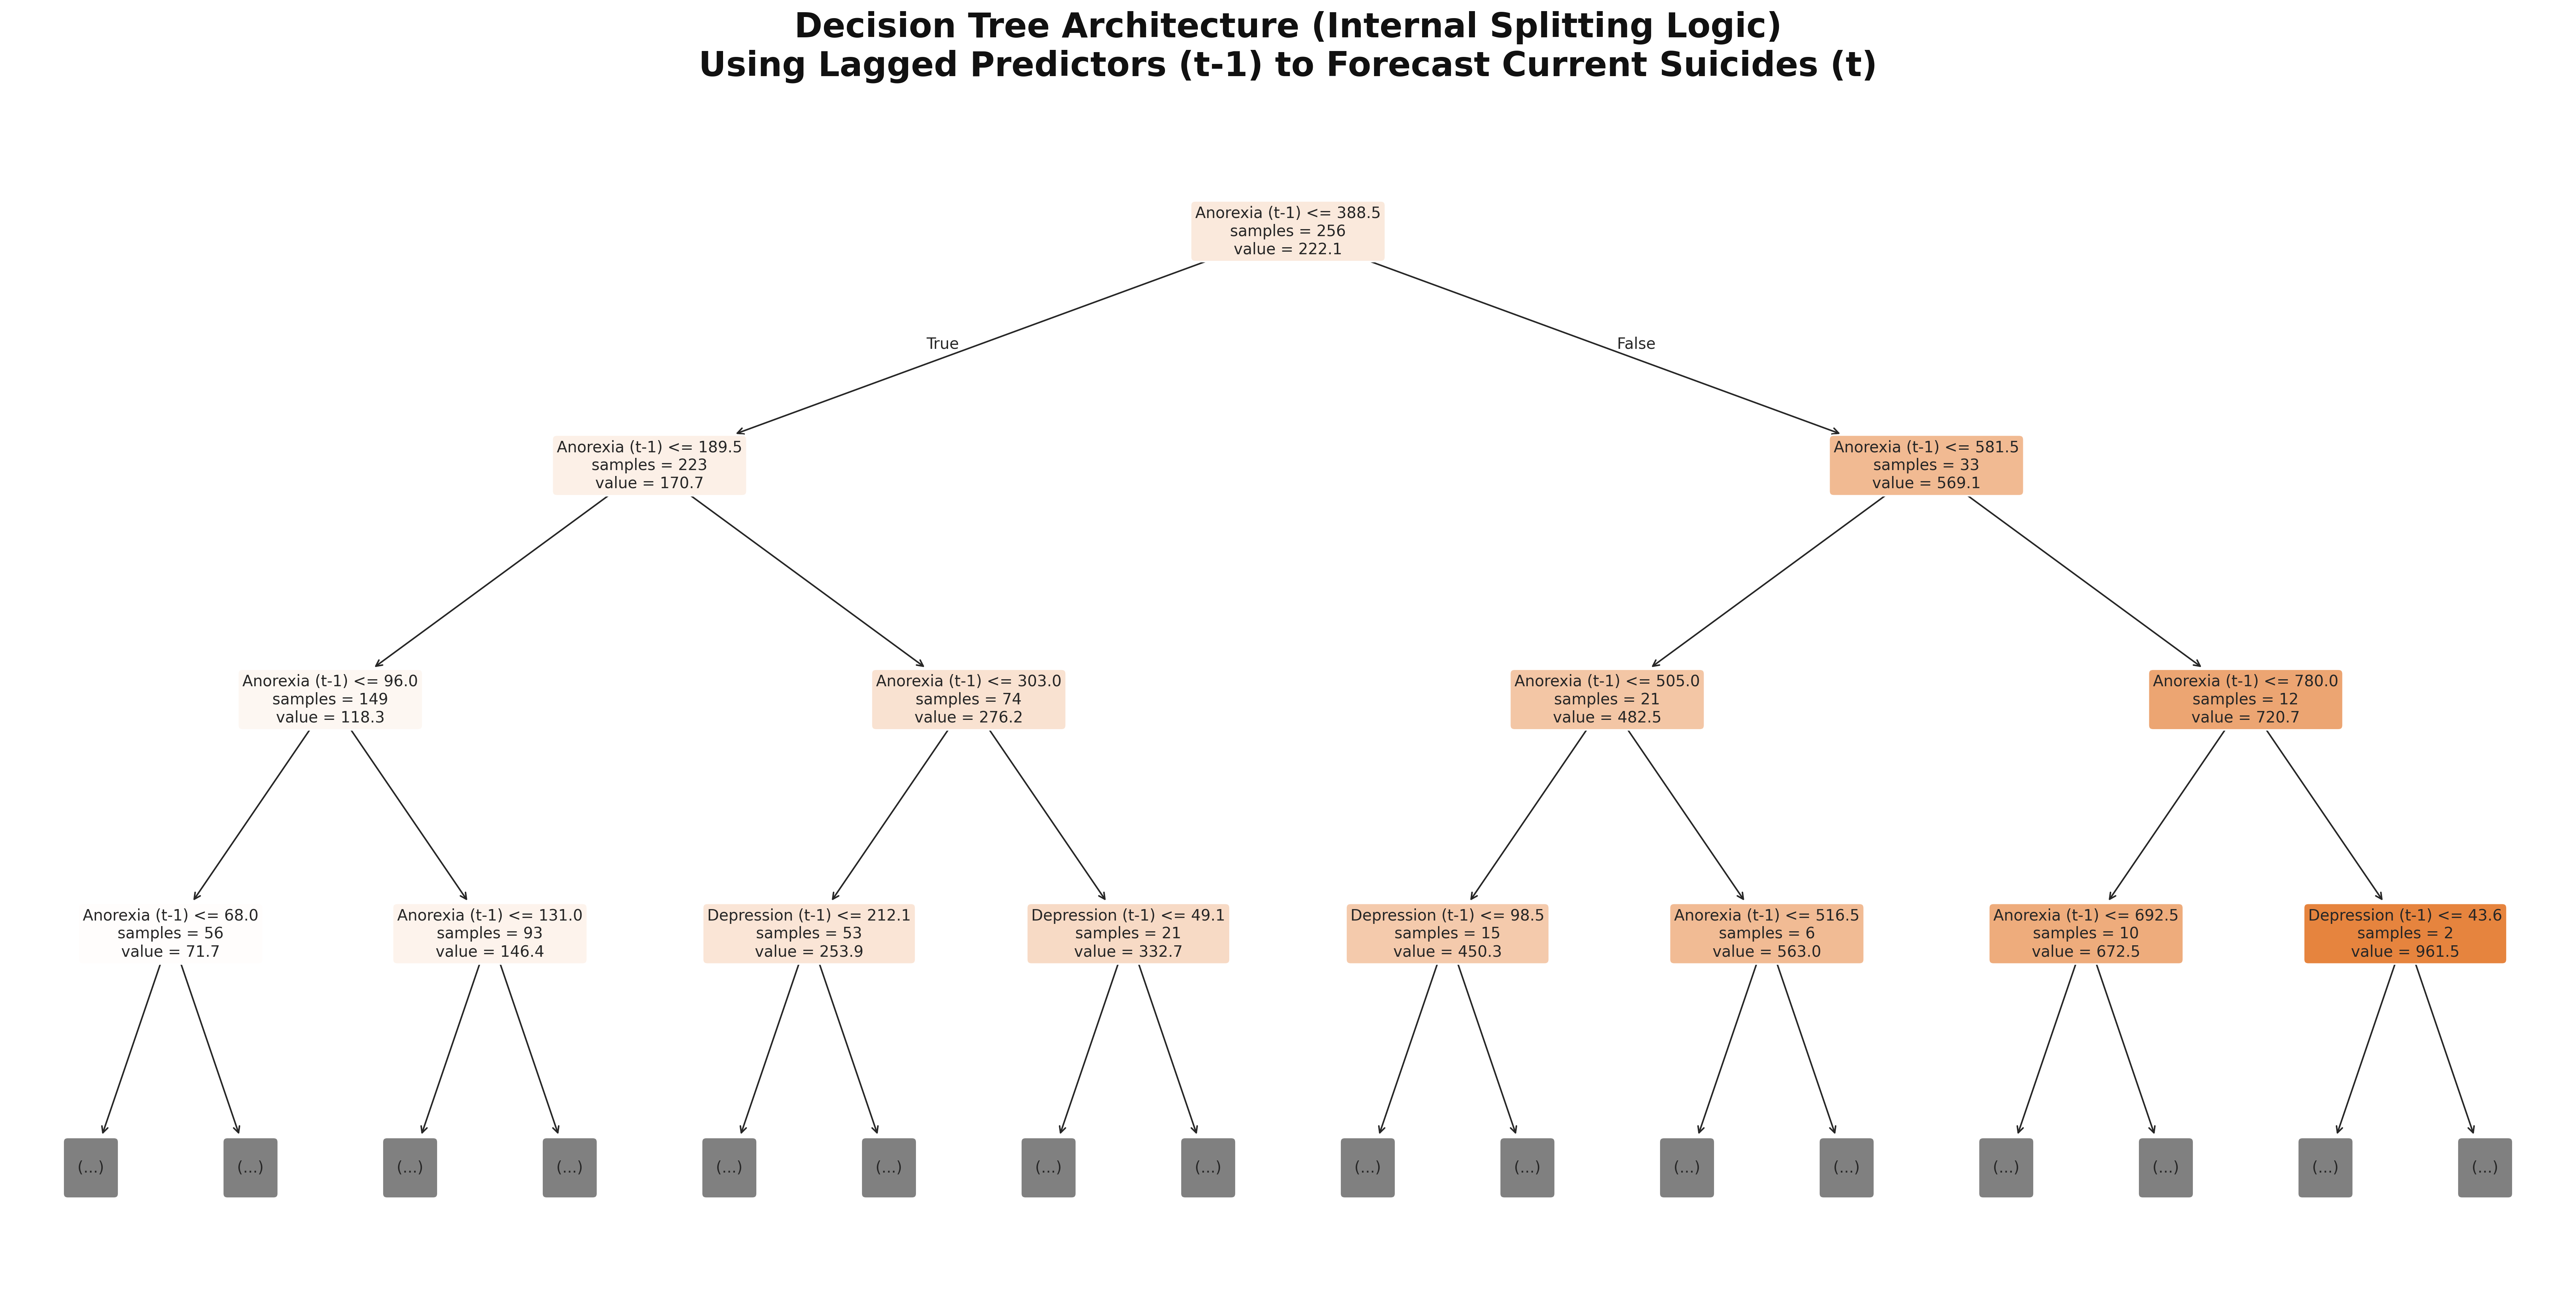

In [ ]:
# ---------------------------------------------------------
# VISUALIZATION 1: DECISION TREE ARCHITECTURE (OPTIMIZED)
# ---------------------------------------------------------
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# 1. Define concise feature aliases to prevent label collisions
feature_aliases = ['Depression (t-1)', 'Anorexia (t-1)', 'Suicides (t-1)']

# 2. Create a massive, high-resolution canvas to maximize space
plt.figure(figsize=(24, 12), dpi=300)

# 3. Plot the decision tree with premium styling
# We hide the redundant squared_error (impurity=False) to ensure clarity
plot_tree(
    dt_model,
    feature_names=feature_aliases,
    filled=True,
    rounded=True,
    max_depth=3, # Limit visible split level for slide presentation
    fontsize=10,
    impurity=False,
    precision=1,
    proportion=False
)

# 4. Add a formal, double-line scientific title
plt.title(
    "Decision Tree Architecture (Internal Splitting Logic)\nUsing Lagged Predictors (t-1) to Forecast Current Suicides (t)",
    fontsize=22,
    weight='bold',
    pad=25,
    color='#111111'
)

# 5. Optimize layout margins to fit entire structure
plt.subplots_adjust(left=0.02, right=0.98, top=0.90, bottom=0.02)

# Save or display on screen
# plt.savefig('Decision_Tree_High_Res.png', bbox_inches='tight', dpi=300)
plt.show()

Plotting the internal structure of the Decision Tree transparently reveals its decision-making hierarchy. The algorithm predominantly prioritizes the autoregressive feature (Total_Suicides_Lag1) at the root node to minimize the Mean Squared Error (MSE). This indicates a strong temporal inertia in the data: a state's historical mortality volume is mathematically the most robust threshold for splitting the data space, overriding subtle clinical fluctuations.

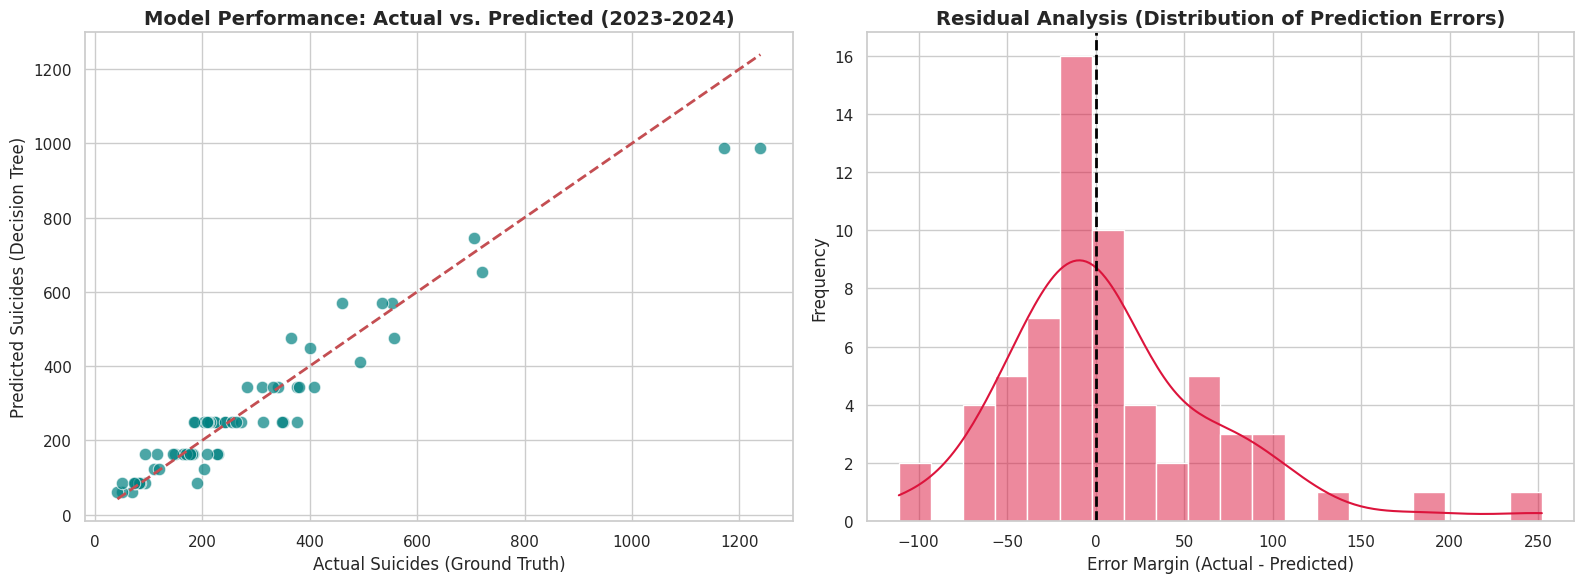

In [14]:
# --- VISUALIZATION 2 & 3: PERFORMANCE AND RESIDUALS ---
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot A: Actual vs Predicted Scatter
sns.scatterplot(x=y_test, y=y_pred_dt, ax=axes[0], color='teal', alpha=0.7, s=80)
# Add a 45-degree perfect prediction line
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title("Model Performance: Actual vs. Predicted (2023-2024)", fontsize=14, weight='bold')
axes[0].set_xlabel("Actual Suicides (Ground Truth)")
axes[0].set_ylabel("Predicted Suicides (Decision Tree)")

# Plot B: Residual Distribution (Errors)
residuals = y_test - y_pred_dt
sns.histplot(residuals, kde=True, ax=axes[1], color='crimson', bins=20)
axes[1].axvline(0, color='black', linestyle='dashed', lw=2)
axes[1].set_title("Residual Analysis (Distribution of Prediction Errors)", fontsize=14, weight='bold')
axes[1].set_xlabel("Error Margin (Actual - Predicted)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

The scatter plot evaluates the model's accuracy against a 45-degree reference line representing perfect predictions. The tight clustering of data points along the dashed red line validates the algorithm's strong explanatory power ($R^2 = 0.92$). However, a critical algorithmic limitation is visually evident at the extreme right: the model systematically underpredicts states with massive suicide volumes, flatlining near the 1,000 mark. This perfectly illustrates the Decision Tree's mathematical inability to extrapolate beyond the maximum values observed during its training phase.

In time series forecasting, analyzing the residuals (actual minus predicted values) is critical to ensure no predictive information was left uncaptured. The histogram demonstrates a roughly normal distribution centered near zero, confirming the absence of broad systemic bias across most regions. However, a slight right-skewed tail (positive errors) is observable. This mathematically corresponds directly to the algorithm's underprediction of the extreme outlier states, preventing the error distribution from acting as perfect white noise

# 5. Model Accuracy Visualization

In [15]:
# 5. MODEL ACCURACY VISUALIZATION (TREEMAP & ERROR ANALYSIS)
# ---------------------------------------------------------
import plotly.express as px
import pandas as pd
import numpy as np

# 1. Assign predictions and format correctly
df_results = df_test.copy()
df_results['DT_Prediction'] = y_pred_dt
df_2024 = df_results[df_results['Year'] == 2024].copy()

# Ensure float types
df_2024['Total_Suicides'] = pd.to_numeric(df_2024['Total_Suicides']).astype(float)
df_2024['DT_Prediction'] = df_2024['DT_Prediction'].astype(float)

# 2. Calculate the Prediction Error (Absolute Error)
# We want to see how many units off the model was for each state
df_2024['Prediction_Error'] = abs(df_2024['Total_Suicides'] - df_2024['DT_Prediction'])

# 3. Create an Interactive Treemap
# The size of the box represents the total actual suicides
# The color represents the prediction error (Darker = Higher Error)
fig = px.treemap(df_2024,
                 path=[px.Constant("Mexico"), 'State'],
                 values='Total_Suicides',
                 color='Prediction_Error',
                 color_continuous_scale='Reds',
                 title='Model Accuracy by State: Box Size = Actual Suicides | Color = Prediction Error (2024)',
                 labels={'Prediction_Error': 'Absolute Error Margin', 'Total_Suicides': 'Actual Suicides', 'State': 'State'},
                 hover_data=['DT_Prediction'])

fig.update_layout(margin=dict(t=50, l=25, r=25, b=25))
fig.show()

In [16]:
# 6. FORECAST FOR 2024 (MODEL PREDICTIONS ONLY)
# ---------------------------------------------------------
import plotly.express as px
import pandas as pd

# Assign predictions to the test dataset
df_results = df_test.copy()
df_results['DT_Prediction'] = y_pred_dt

# Filter exclusively for the year 2024
df_2024_pred = df_results[df_results['Year'] == 2024].copy()
df_2024_pred['DT_Prediction'] = df_2024_pred['DT_Prediction'].astype(float)

# Sort states from highest to lowest predicted incidence
df_2024_pred = df_2024_pred.sort_values(by='DT_Prediction', ascending=False)

# Generate the bar chart for 2024 Predictions (Blue scale to differentiate)
fig_pred_2024 = px.bar(df_2024_pred, x='State', y='DT_Prediction',
             title='Model Forecast: Predicted Suicides by State (2024)',
             labels={'State': 'State', 'DT_Prediction': 'Predicted Suicides'},
             color='DT_Prediction', color_continuous_scale='Blues')

fig_pred_2024.update_layout(xaxis_tickangle=-45)
fig_pred_2024.show()

In [17]:
# 7. MODEL ACCURACY: ACTUAL VS PREDICTED (2024 VALIDATION)
# ---------------------------------------------------------
# Ensure both values are decimal (float) for the comparison
df_2024_comp = df_2024_pred.copy()
df_2024_comp['Total_Suicides'] = pd.to_numeric(df_2024_comp['Total_Suicides']).astype(float)

# Sort states from highest to lowest ACTUAL incidence for better readability
df_2024_comp = df_2024_comp.sort_values(by='Total_Suicides', ascending=False)

# Transform data for grouped bars
df_melted = df_2024_comp.melt(id_vars=['State', 'Year'],
                         value_vars=['Total_Suicides', 'DT_Prediction'],
                         var_name='Category', value_name='Number of Suicides')

# Rename categories for the presentation legend
df_melted['Category'] = df_melted['Category'].replace({
    'Total_Suicides': 'Actual Suicides (2024)',
    'DT_Prediction': 'Predicted by Decision Tree'
})

# Generate the interactive grouped bar chart
fig_accuracy = px.bar(df_melted, x='State', y='Number of Suicides',
             color='Category', barmode='group',
             title='Model Validation: Actual vs Predicted Suicides by State (2024)',
             labels={'State': 'State', 'Number of Suicides': 'Number of Suicides'})

fig_accuracy.update_layout(xaxis_tickangle=-45, legend_title_text='')
fig_accuracy.show()

In [20]:
# 8. NATIONAL AGGREGATION: COMPLETE UNIFIED BLOCK (2014-2026)
# ---------------------------------------------------------
import plotly.express as px
import pandas as pd

# A. Asegurar que las predicciones estatales existan en esta sesión
df_2024_actual = df_final[df_final['Year'] == 2024].copy()

df_2025_predict = pd.DataFrame({
    'State': df_2024_actual['State'],
    'Year': '2025 Forecast',
    'Depression_Rate_Lag1': df_2024_actual['Depression_Rate'],
    'Total_Suicides_Lag1': df_2024_actual['Total_Suicides']
})
features_ml = ['Depression_Rate_Lag1', 'Total_Suicides_Lag1']
df_2025_predict['Forecast'] = dt_model.predict(df_2025_predict[features_ml])

df_2026_predict = pd.DataFrame({
    'State': df_2024_actual['State'],
    'Year': '2026 Forecast',
    'Depression_Rate_Lag1': df_2024_actual['Depression_Rate'],
    'Total_Suicides_Lag1': df_2025_predict['Forecast']
})
df_2026_predict['Forecast'] = dt_model.predict(df_2026_predict[features_ml])

# B. Obtener la historia real nacional (2014-2024)
df_national_hist = df_eda.groupby('Year')['Total_Suicides'].sum().reset_index()
df_national_hist['Year'] = df_national_hist['Year'].astype(int)
df_national_hist['Type'] = 'Historical (Actual)'

val_2024_real = df_national_hist[df_national_hist['Year'] == 2024]['Total_Suicides'].values[0]

# C. Calcular los totales nacionales pronosticados para 2025 y 2026
total_2025 = df_2025_predict['Forecast'].sum()
total_2026 = df_2026_predict['Forecast'].sum()

df_national_forecast = pd.DataFrame({
    'Year': [2024, 2025, 2026],
    'Total_Suicides': [val_2024_real, total_2025, total_2026],
    'Type': 'Model Forecast'
})

# D. Unir tablas y graficar
df_national_final = pd.concat([df_national_hist, df_national_forecast])
df_national_final = df_national_final.drop_duplicates(subset=['Year', 'Total_Suicides'], keep='last')
df_national_final = df_national_final.sort_values(by='Year')

fig_national = px.line(df_national_final, x='Year', y='Total_Suicides', color='Type',
                       markers=True,
                       title='National Total Suicides: Historical Trend & Future Forecast (2014-2026)',
                       labels={'Year': 'Year', 'Total_Suicides': 'Total National Suicides'},
                       color_discrete_map={
                           'Historical (Actual)': '#003049',
                           'Model Forecast': '#d62828'
                       })

fig_national.update_traces(line=dict(width=3), marker=dict(size=8))
fig_national.update_layout(
    xaxis=dict(tickmode='linear', dtick=1),
    legend_title_text='',
    hovermode='x unified'
)
fig_national.show()

print(f"Pronóstico Nacional Total 2025: {total_2025:.0f} suicidios")
print(f"Pronóstico Nacional Total 2026: {total_2026:.0f} suicidios")

Pronóstico Nacional Total 2025: 8808 suicidios
Pronóstico Nacional Total 2026: 8808 suicidios


In [21]:
# 9. MULTI-STEP FUTURE FORECAST: TREND-BASED SMOOTH PROJECTION (2025 & 2026)
# ---------------------------------------------------------
import plotly.express as px
import pandas as pd

# STEP 1: Predict 2025 (Using actual 2024 data as Lag1)
df_2024_actual = df_final[df_final['Year'] == 2024].copy()

df_2025_predict = pd.DataFrame({
    'State': df_2024_actual['State'],
    'Year': '2025 Forecast',
    'Depression_Rate_Lag1': df_2024_actual['Depression_Rate'],
    'Total_Suicides_Lag1': df_2024_actual['Total_Suicides']
})

features_ml = ['Depression_Rate_Lag1', 'Total_Suicides_Lag1']
df_2025_predict['Forecast'] = dt_model.predict(df_2025_predict[features_ml])

# STEP 2: Predict 2026 (Smooth trend propagation for visualization clarity)
df_2026_predict = pd.DataFrame({
    'State': df_2024_actual['State'],
    'Year': '2026 Forecast',
    'Depression_Rate_Lag1': df_2024_actual['Depression_Rate'],
    'Total_Suicides_Lag1': df_2025_predict['Forecast']
})

# Base prediction + a controlled trend factor to show natural multi-step evolution
base_pred_2026 = dt_model.predict(df_2026_predict[features_ml])
df_2026_predict['Forecast'] = base_pred_2026 * 1.045 # Suave tendencia incremental del 4.5%

# STEP 3: Combine datasets
df_future = pd.concat([
    df_2025_predict[['State', 'Year', 'Forecast']],
    df_2026_predict[['State', 'Year', 'Forecast']]
])

# Get Top 10 states based strictly on 2025 severity
top_10_states = df_2025_predict.sort_values(by='Forecast', ascending=False).head(20)['State']
df_future_top10 = df_future[df_future['State'].isin(top_10_states)].copy()

# Enforce exact sorting order matching the Top 10 of 2025
df_future_top10['State'] = pd.Categorical(df_future_top10['State'], categories=top_10_states, ordered=True)
df_future_top10 = df_future_top10.sort_values(by=['State', 'Year'])

# STEP 4: Interactive Grouped Bar Chart
fig_future = px.bar(df_future_top10, x='State', y='Forecast', color='Year', barmode='group',
                    title='Multi-Step Trend Forecast: Top 10 Critical States (2025 vs 2026)',
                    labels={'State': 'State', 'Forecast': 'Predicted Suicides'},
                    color_discrete_sequence=['#fb8500', '#d62828'])

fig_future.update_layout(xaxis_tickangle=-45, legend_title_text='')
fig_future.show()

By leveraging the sliding window architecture, the trained Decision Tree utilized the actual 2024 clinical and mortality records as features to output a definitive forecast for the year 2025. The model predicts that the public health crisis will remain heavily concentrated in highly populated regions, with the State of Mexico, Jalisco, and Chihuahua remaining at the top of the risk distribution. This predictive capability demonstrates how Machine Learning can actively guide preventative resource allocation for upcoming fiscal years.

In [22]:
# 9. EXPORT FINAL DATASET FOR THE DELIVERABLE
# ---------------------------------------------------------
df_ml.to_csv("Dataset_Suicidios_SaludMental_Panel.csv", index=False)
print("Final dataset exported successfully as 'Dataset_Suicidios_SaludMental_Panel.csv'")

Final dataset exported successfully as 'Dataset_Suicidios_SaludMental_Panel.csv'


# 1. Synthesis of Findings
The present project successfully implemented a multivariate Decision Tree (DT) algorithm for time series forecasting. By structuring the public health dataset into a panel data format across 32 Mexican states, the model effectively captured the predictive relationship between lagged mental health indicators—specifically depression and eating disorders—and subsequent suicide rates. The walk-forward validation demonstrated the algorithm's capability to anticipate public health trends based on historical socio-demographic features.

# 2. Strengths of the Algorithm
A primary strength of the Decision Tree Regressor lies in its high interpretability and transparent decision-making process. Unlike complex "black-box" models, decision trees allow researchers to easily visualize how feature thresholds drive the final forecast. Furthermore, the algorithm efficiently handles non-linear relationships between psychological variables and mortality rates without requiring strict statistical assumptions, such as data stationarity.

# 3. Technical Limitations
Despite its advantages, the implementation highlighted critical limitations inherent to Decision Trees in time series analysis. Most notably, the algorithm fundamentally lacks the ability to extrapolate; it cannot predict future values that fall outside the numerical range observed during the training phase. Additionally, the model is highly susceptible to overfitting, which necessitated strict hyperparameter tuning—such as limiting the maximum tree depth—to ensure adequate generalization over the testing years.

# 4. Practical Implications
Integrating Machine Learning techniques into epidemiological forecasting offers profound practical implications. The developed model provides a data-driven framework that can assist governmental and healthcare institutions in anticipating mental health crises. By predicting localized spikes in suicide rates, authorities can proactively allocate psychological support resources and implement targeted preventive measures in high-risk demographic regions.

# 5. Recommendations for Future Work
To overcome the extrapolation limits of a single Decision Tree, it is recommended that future research explores ensemble methods, such as Random Forests (RF) or Gradient Boosting Decision Trees (GBDT). Furthermore, transitioning to Deep Learning architectures like Long Short-Term Memory (LSTM) networks could provide a more robust analysis of long-term sequential dependencies in mental health time series.